# Take the iris dataset and perform KNN. Step 1: EDA - head() , describe () , groupby() Step 2: Feature scaling Step 3: Training the K-NN model on the Training set Step 4: Making the Confusion Matrix & Predicting Accuracy Score Step 5: Making Classification Report Step 6: Comparing Error Rate with the K Value Step 7: Plot the error values against K values Step 8: Finding best K Step 9: Visualize Test Result of KNN

## Step 1 — Import libraries and perform EDA

In [1]:
import sys
import os
import importlib.util
import importlib.metadata

print("Python executable:")
print(sys.executable)

print("\nCurrent working directory:")
print(os.getcwd())

print("\nMatplotlib package information:")
print(importlib.metadata.version("matplotlib"))

spec = importlib.util.find_spec("matplotlib")
print("\nMatplotlib location:")
print(spec.origin if spec else "Not found")

import matplotlib

print("\nImported Matplotlib location:")
print(matplotlib.__file__)

print("\nHas get_data_path:", hasattr(matplotlib, "get_data_path"))

Python executable:
C:\Users\write\OneDrive\Documents\JOB2\.venv\Scripts\python.exe

Current working directory:
C:\Users\write\OneDrive\Documents\JOB2\StatPracticals

Matplotlib package information:
3.11.2

Matplotlib location:
C:\Users\write\OneDrive\Documents\JOB2\.venv\Lib\site-packages\matplotlib\__init__.py

Imported Matplotlib location:
C:\Users\write\OneDrive\Documents\JOB2\.venv\Lib\site-packages\matplotlib\__init__.py

Has get_data_path: True


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

In [4]:
import sys
print(sys.version)
print(sys.executable)

3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
C:\Users\write\OneDrive\Documents\JOB2\.venv\Scripts\python.exe


In [7]:
# Load the Iris dataset
iris = load_iris()

# Convert it into a Pandas DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["Species"] = iris.target

# Display first five records
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 1.3 Understand the target classes

In [8]:
print(iris.target_names)
print(df["Species"].value_counts())

['setosa' 'versicolor' 'virginica']
Species
0    50
1    50
2    50
Name: count, dtype: int64


## 1.4 Use describe()

In [9]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## 1.5 Use groupby()

In [10]:
df.groupby("Species").mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
Species,,,,
0,5.006,3.428,1.462,0.246
1,5.936,2.770,4.260,1.326
2,6.588,2.974,5.552,2.026


# Step 2 — Feature Scaling

## 2.1 Import StandardScaler

In [11]:
from sklearn.preprocessing import StandardScaler

## 2.2 Separate independent and dependent variables

In [13]:
# Independent variables (features)
X = df.drop("Species", axis=1)

# Dependent variable (target)
y = df["Species"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (150, 4)
Target shape: (150,)



# 2.3 Apply feature scaling

## For a proper machine-learning workflow, we'll split the data first and fit the scaler only on the training data. This prevents information from the test set leaking into training.

# Step 3 — Training the KNN Model

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


## 3.2 Scale the training and testing data

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

## 3.3 Import and train KNN

In [16]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_scaled, y_train)

print("KNN Model trained successfully!")

KNN Model trained successfully!


# Step 4 — Confusion Matrix and Accuracy Score

In [17]:
from sklearn.metrics import confusion_matrix, accuracy_score

# Make predictions
y_pred = knn.predict(X_test_scaled)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy Score: 0.9333333333333333
Accuracy Percentage: 93.33333333333333


# Step 5 — Classification Report

In [18]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



# Step 6 — Comparing Error Rate with K Value

In [20]:
error_rate = []

for k in range(1, 21):

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    error = np.mean(predictions != y_test)

    error_rate.append(error)

    print("K =", k, "Error Rate =", error)

K = 1 Error Rate = 0.03333333333333333
K = 2 Error Rate = 0.06666666666666667
K = 3 Error Rate = 0.06666666666666667
K = 4 Error Rate = 0.06666666666666667
K = 5 Error Rate = 0.06666666666666667
K = 6 Error Rate = 0.06666666666666667
K = 7 Error Rate = 0.03333333333333333
K = 8 Error Rate = 0.06666666666666667
K = 9 Error Rate = 0.03333333333333333
K = 10 Error Rate = 0.03333333333333333
K = 11 Error Rate = 0.03333333333333333
K = 12 Error Rate = 0.03333333333333333
K = 13 Error Rate = 0.03333333333333333
K = 14 Error Rate = 0.03333333333333333
K = 15 Error Rate = 0.03333333333333333
K = 16 Error Rate = 0.03333333333333333
K = 17 Error Rate = 0.03333333333333333
K = 18 Error Rate = 0.03333333333333333
K = 19 Error Rate = 0.03333333333333333
K = 20 Error Rate = 0.03333333333333333


# Step 7 — Plot Error Values Against K Values

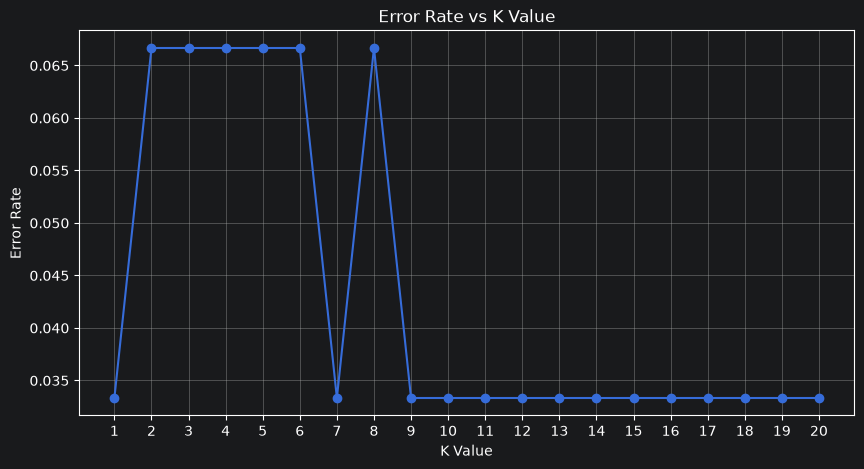

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 21),
    error_rate,
    marker="o"
)

plt.title("Error Rate vs K Value")
plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.xticks(range(1, 21))
plt.grid(True)

plt.show()

# Step 8 — Finding the Best K

In [22]:
best_k = np.argmin(error_rate) + 1

print("Best K Value:", best_k)
print("Minimum Error Rate:", min(error_rate))
print("Best Accuracy:", (1 - min(error_rate)) * 100)

Best K Value: 1
Minimum Error Rate: 0.03333333333333333
Best Accuracy: 96.66666666666667


# Step 9 — Visualize KNN Test Results

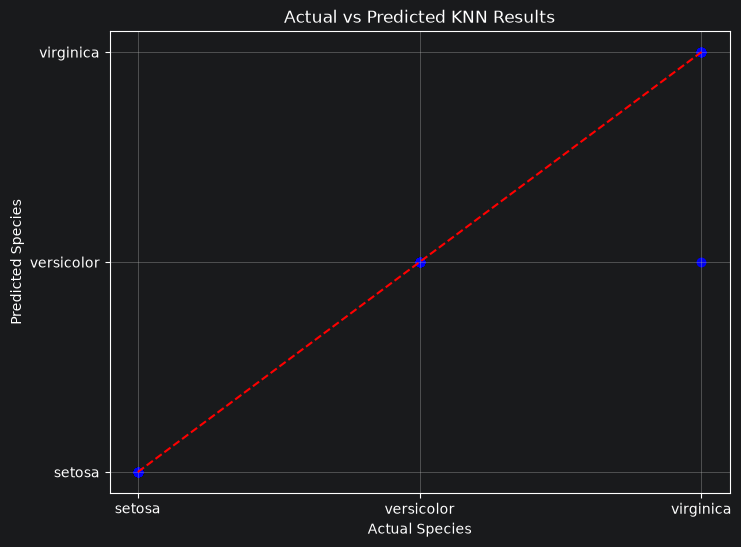

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    color="blue",
    alpha=0.7
)

plt.plot(
    [0, 2],
    [0, 2],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Species")
plt.ylabel("Predicted Species")
plt.title("Actual vs Predicted KNN Results")

plt.xticks([0, 1, 2], iris.target_names)
plt.yticks([0, 1, 2], iris.target_names)

plt.grid(True)
plt.show()